# Random and structured directions

In [1]:
import torch

from eszd import SSZD
from eszd.directions import SphericalDirections, HouseholderQRDirections, GaussianDirections, HouseholderReflection, RandomCoords, DirectionMatrix
import matplotlib.pyplot as plt

from math import sqrt

In [2]:
def target(x, z = None):
    return x.square().mean(dim=1)

In [4]:

d = 100
l = d//5
alpha = lambda t: l/d * 20.0# * 1/sqrt(t)
h = lambda t : 1e-9 / sqrt(t)
gaussian_P = SphericalDirections(d=d, l=l, dtype=torch.float64)
structured_P = HouseholderQRDirections(d=d, l=l, dtype=torch.float64)

In [5]:
opt_st = SSZD(structured_P, alpha=alpha, h=h)
opt_gd = SSZD(gaussian_P, alpha=alpha, h=h)

In [6]:
T = 500
x0 = torch.full((1, d), 1e4)

ris_st = opt_st.optimize(target, x0, T=T)
ris_gd = opt_gd.optimize(target, x0, T=T)


In [7]:
trace_st = []
trace_gd = []

for i in range(len(ris_st[2])):
    for _ in range(l):
        trace_st.append(ris_st[2][i])
        trace_gd.append(ris_gd[2][i])


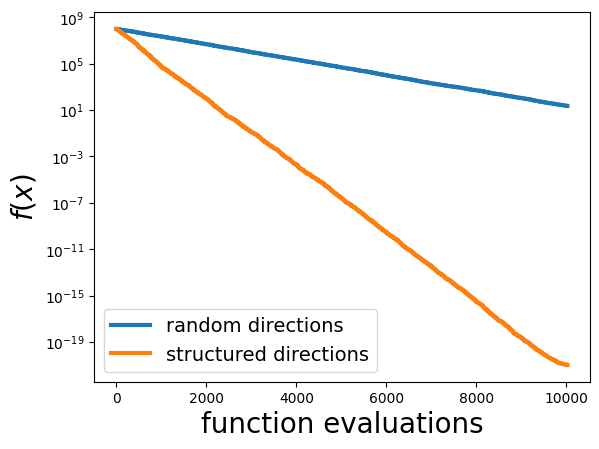

In [8]:
fig, ax = plt.subplots()
ax.plot(range(len(trace_gd)), trace_gd,'-', lw=3, label="random directions")
ax.plot(range(len(trace_st)), trace_st,'-', lw=3, label="structured directions")
ax.set_yscale("log")
ax.set_xlabel("function evaluations", fontsize=20)
ax.set_ylabel("$f(x)$", fontsize=20)
ax.legend(fontsize=14)
plt.savefig("structured_vs_random.pdf", bbox_inches='tight')



## Random vs Structured: Computational Cost

In [11]:
import time 


dims = [1, 10, 100, 1000, 10000]
reps = 5

def compute_time(P):
    it_time = time.time()
    P()
    it_time = time.time() - it_time
    return it_time

ctimes = {
    'gaussian' : [[] for _ in range(len(dims))],
    'coords' : [[] for _ in range(len(dims))],
    'spherical' : [[] for _ in range(len(dims))],
    'householder' : [[] for _ in range(len(dims))]
}

device = 'cpu'
dtype = torch.float32

for i, d in enumerate(dims):
    C = RandomCoords(d=d,l=d,dtype=dtype, device =device)
    S = SphericalDirections(d=d, l=d, dtype=dtype, device =device)
    G = GaussianDirections(d = d, l = d,dtype=dtype, device =device)
    H = HouseholderReflection(d = d, l = d,dtype=dtype, device =device)
    C()
    S()
    G()
    H()

    for r in range(reps):
        
        ctimes['gaussian'][i].append(compute_time(G))
        ctimes['spherical'][i].append(compute_time(S))
        ctimes['coords'][i].append(compute_time(C))
        ctimes['householder'][i].append(compute_time(H))



RuntimeError: No CUDA GPUs are available

In [ ]:
import numpy as np
ctimes['gaussian'] = np.mean(ctimes['gaussian'],1)
ctimes['spherical'] = np.mean(ctimes['spherical'],1)
ctimes['coords'] = np.mean(ctimes['coords'],1)
ctimes['householder'] = np.mean(ctimes['householder'],1)

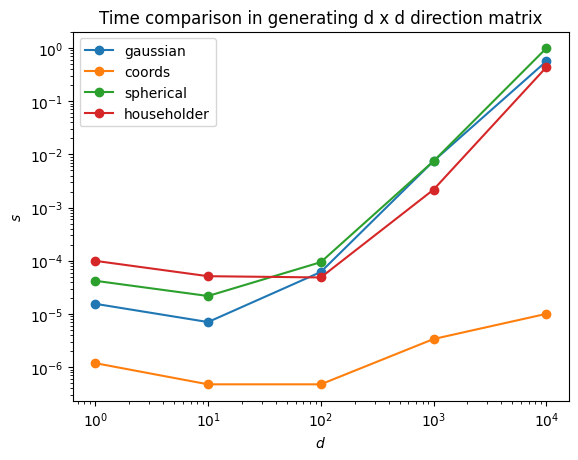

In [ ]:


fig, ax = plt.subplots()

ax.set_title("Time comparison in generating d x d direction matrix")
for (k, v) in ctimes.items():
    ax.plot(dims, v, 'o-', label=k)
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xlabel("$d$")
ax.set_ylabel("$s$")
ax.legend()
fig.savefig("./time_comparison_dxd_{}.pdf".format(device), bbox_inches='tight')


In [5]:
v = torch.randn()

v/=v.norm(p=2)

from math import sqrt

H = sqrt(5/3) * (torch.eye(5, 3) - 2 * torch.outer(v, v[:3]))

print(H)

print(H.T @ H * 3/5)

TypeError: randn() received an invalid combination of arguments - got (), but expected one of:
 * (tuple of ints size, *, torch.Generator generator, tuple of names names, torch.dtype dtype, torch.layout layout, torch.device device, bool pin_memory, bool requires_grad)
 * (tuple of ints size, *, torch.Generator generator, Tensor out, torch.dtype dtype, torch.layout layout, torch.device device, bool pin_memory, bool requires_grad)
 * (tuple of ints size, *, Tensor out, torch.dtype dtype, torch.layout layout, torch.device device, bool pin_memory, bool requires_grad)
 * (tuple of ints size, *, tuple of names names, torch.dtype dtype, torch.layout layout, torch.device device, bool pin_memory, bool requires_grad)


In [46]:
nrm = sqrt(5/3)
I = torch.eye(5, 3)
c1 = nrm * (I[:, :1].reshape(-1, 1) - 2 * torch.outer(v, v[0:1]))

print(c1)

tensor([[ 1.1733],
        [ 0.1118],
        [ 0.1959],
        [-0.2766],
        [-0.4033]])


# ESZD & SimAnnealing

In [43]:
from torch.linalg import householder_product

A = torch.eye(4, 2)
tau = torch.randn((2))

H = householder_product(A, tau)



print(H)
print(H @ H.T)

tensor([[1.6705, 0.0000],
        [0.0000, 2.3140],
        [0.0000, 0.0000],
        [0.0000, 0.0000]])
tensor([[2.7906, 0.0000, 0.0000, 0.0000],
        [0.0000, 5.3547, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000]])
